# Détection du risque d'épuisement (burnout) chez les étudiants
**Équipe 6 : Olliesk Doli et Samuel-William Mpiana**

Dataset : *AI Dependency, Career Anxiety and Student Burnout* (Kaggle).

Ce notebook a trois parties :
- **Partie 1 : exploration (EDA)**, sections 1 à 5 : aperçu, qualité des données, variable cible, distributions, liens avec le burnout.
- **Partie 2 : préparation des données**, section 6 : nettoyage, ys des deux volets, familles de colonnes, pipeline de prétraitement, séparation 60 / 20 / 20.
- **Partie 3 : modélisation**, sections 7 et 8 : 3 modèles de classification comparés sur la **validation** pour chacun des deux volets, tableau de résultats, conclusions.

Le jeu de **test** est mis de côté et n'est **pas** utilisé dans ce notebook : on le garde pour l'évaluation finale, après l'optimisation.

# Partie 1 : exploration des données (EDA)

## 1. Chargement et aperçu

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

In [2]:
chemin = "ai_dependency_career_anxiety_students.csv"
df = pd.read_csv(chemin)

print("Nombre de lignes   :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes   : 15000
Nombre de colonnes : 30


In [3]:
df.head()

,student_id,age,gender,degree_type,stream,year_of_study,college_tier,urban_or_rural,daily_ai_tool_usage_hrs,primary_ai_tools_used,uses_ai_for_assignments,ai_replaces_own_thinking_score,ai_dependency_score,placement_anxiety_score,fear_of_job_loss_to_ai,career_clarity_score,internship_experience,weekly_job_application_count,resume_confidence_score,interview_anxiety_score,daily_study_hours,self_learning_hours_per_week,skill_development_courses_taken,social_media_hrs_per_day,sleep_hours,stress_level,burnout_score,motivation_score,seeks_career_counseling,overall_career_readiness_score
0,STU_00001,25,Male,B.Tech/B.E.,Engineering (Non-CS),3,Tier 3,Rural,0.3,Perplexity,Never,1,1,3,2,6,2,11,5,2,3.5,8.7,2,1.5,8.5,1,3,6,0.0,9.09
1,STU_00002,20,Female,B.Tech/B.E.,Engineering (Non-CS),4,Tier 3,Urban,1.9,ChatGPT,Rarely,3,7,5,3,8,2,19,4,7,2.4,8.2,3,4.2,8.3,4,5,3,0.0,6.03
2,STU_00003,25,Female,MBA,CS/IT,1,Tier 3,Urban,3.6,Gemini,Sometimes,4,7,6,3,6,1,15,3,6,2.3,16.4,1,2.3,7.0,5,9,3,1.0,6.68
3,STU_00004,23,Male,B.Tech/B.E.,CS/IT,1,Tier 1,Urban,4.1,GitHub Copilot,Frequently,4,4,3,4,7,3,8,5,4,7.7,15.0,3,2.6,7.2,6,6,6,0.0,7.71
4,STU_00005,22,Female,MBA,CS/IT,1,Tier 1,Urban,3.4,ChatGPT,Sometimes,4,10,8,5,3,3,5,4,9,2.4,1.1,2,1.9,8.0,3,5,4,0.0,4.64


In [4]:
df.dtypes

student_id                             str
age                                  int64
gender                                 str
degree_type                            str
stream                                 str
year_of_study                        int64
college_tier                           str
urban_or_rural                         str
daily_ai_tool_usage_hrs            float64
primary_ai_tools_used                  str
uses_ai_for_assignments                str
ai_replaces_own_thinking_score       int64
ai_dependency_score                  int64
placement_anxiety_score              int64
fear_of_job_loss_to_ai               int64
career_clarity_score                 int64
internship_experience                int64
weekly_job_application_count         int64
resume_confidence_score              int64
interview_anxiety_score              int64
daily_study_hours                  float64
self_learning_hours_per_week       float64
skill_development_courses_taken      int64
social_medi

## 2. Qualité des données

### 2.1 Valeurs manquantes

In [5]:
nb_manq = df.isna().sum()
pct_manq = (nb_manq / len(df) * 100).round(2)

resume_manq = pd.DataFrame({
    "nombre_manquant": nb_manq,
    "pourcentage_manquant": pct_manq,
})
resume_manq[resume_manq["nombre_manquant"] > 0]

,nombre_manquant,pourcentage_manquant
primary_ai_tools_used,3215,21.43
self_learning_hours_per_week,233,1.55
social_media_hrs_per_day,210,1.40
sleep_hours,203,1.35
seeks_career_counseling,220,1.47


La colonne `primary_ai_tools_used` est vide pour 21 % des étudiants. Vérifions si ce sont ceux qui n'utilisent pas d'IA.

In [6]:
sans_outil = df[df["primary_ai_tools_used"].isna()]
avec_outil = df[df["primary_ai_tools_used"].notna()]

print("Usage quotidien moyen d'IA (heures) quand l'outil principal est manquant :",
      round(sans_outil["daily_ai_tool_usage_hrs"].mean(), 3))
print("Usage quotidien moyen d'IA (heures) quand l'outil principal est renseigné :",
      round(avec_outil["daily_ai_tool_usage_hrs"].mean(), 3))

Usage quotidien moyen d'IA (heures) quand l'outil principal est manquant : 0.007
Usage quotidien moyen d'IA (heures) quand l'outil principal est renseigné : 2.561


**Conclusion :** ces valeurs manquantes ne sont pas des erreurs. Elles signifient « aucun outil utilisé ». On les remplacera par la catégorie `Aucun`.

In [7]:
cols_manq = [
    "self_learning_hours_per_week", "social_media_hrs_per_day",
    "sleep_hours", "seeks_career_counseling",
]

for nom_colonne in cols_manq:
    moy_presence = df.groupby(df[nom_colonne].isna())["burnout_score"].mean().round(2)
    print(nom_colonne, "-> burnout moyen (renseigné / manquant) :",
          moy_presence[False], "/", moy_presence[True])

self_learning_hours_per_week -> burnout moyen (renseigné / manquant) : 5.47 / 5.47
social_media_hrs_per_day -> burnout moyen (renseigné / manquant) : 5.47 / 5.42
sleep_hours -> burnout moyen (renseigné / manquant) : 5.47 / 5.36
seeks_career_counseling -> burnout moyen (renseigné / manquant) : 5.48 / 5.27


Les quatre autres colonnes ont environ 1,5 % de manquants, sans lien visible avec le burnout. On les remplacera par la **médiane**, calculée sur le jeu d'entraînement seulement.

### 2.2 Doublons et identifiants

In [8]:
print("Lignes dupliquées      :", df.duplicated().sum())
print("Identifiants uniques   :", df["student_id"].nunique(), "sur", len(df))

Lignes dupliquées      : 0
Identifiants uniques   : 15000 sur 15000


### 2.3 Cohérence des valeurs

In [9]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,15000.0,21.38,2.01,18.0,20.0,21.0,22.00,28.0
year_of_study,15000.0,2.10,0.99,1.0,1.0,2.0,3.00,4.0
daily_ai_tool_usage_hrs,15000.0,2.01,1.74,0.0,0.4,1.8,3.20,8.0
ai_replaces_own_thinking_score,15000.0,2.99,1.31,1.0,2.0,3.0,4.00,5.0
ai_dependency_score,15000.0,4.54,2.32,1.0,3.0,4.0,6.00,10.0
placement_anxiety_score,15000.0,5.91,2.55,1.0,4.0,6.0,8.00,10.0
fear_of_job_loss_to_ai,15000.0,3.55,1.18,1.0,3.0,4.0,5.00,5.0
career_clarity_score,15000.0,5.03,2.20,1.0,3.0,5.0,6.00,10.0
internship_experience,15000.0,1.72,1.07,0.0,1.0,2.0,2.00,4.0
weekly_job_application_count,15000.0,10.64,6.40,0.0,6.0,10.0,15.00,35.0


In [10]:
heures_tot = (
    df["daily_ai_tool_usage_hrs"]
    + df["daily_study_hours"]
    + df["social_media_hrs_per_day"]
    + df["sleep_hours"]
)
print("Étudiants dont les heures déclarées dépassent 24 h par jour :", (heures_tot > 24).sum())

Étudiants dont les heures déclarées dépassent 24 h par jour : 3


Seulement 3 lignes sur 15 000 dépassent 24 h. C'est négligeable, on les conserve.

## 3. Variable cible

Le fichier contient un `burnout_score` de 1 à 10, mais **pas de niveau de risque**. Pour faire de la classification, il faut le créer.

Découpage retenu (à valider avec l'équipe et le professeur) :
- **Faible** : score de 1 à 4
- **Moyen** : score de 5 à 6
- **Élevé** : score de 7 à 10

Ce découpage donne trois classes d'effectifs comparables. D'autres découpages sont comparés en section 7.5.

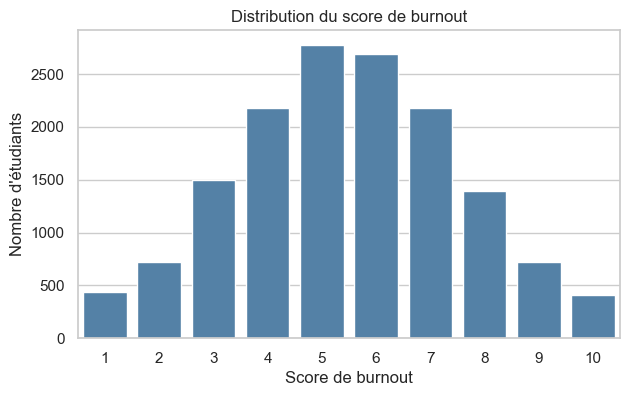

In [11]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="burnout_score", color="steelblue")
plt.title("Distribution du score de burnout")
plt.xlabel("Score de burnout")
plt.ylabel("Nombre d'étudiants")
plt.show()

In [12]:
df["niveau_burnout"] = pd.cut(
    df["burnout_score"],
    bins=[0, 4, 6, 10],
    labels=["Faible", "Moyen", "Élevé"],
)

rep_niv = df["niveau_burnout"].value_counts().reindex(["Faible", "Moyen", "Élevé"])
pd.DataFrame({
    "nombre": rep_niv,
    "pourcentage": (rep_niv / len(df) * 100).round(1),
})

,nombre,pourcentage
niveau_burnout,,
Faible,4832,32.2
Moyen,5461,36.4
Élevé,4707,31.4


Les trois classes sont équilibrées (Faible 32 %, Moyen 36 %, Élevé 31 %). Pas besoin de rééquilibrage comme SMOTE.

### Variable cible du volet 2 : `seeks_career_counseling`

In [13]:
rep_soutien = df["seeks_career_counseling"].value_counts().sort_index()   # les vides sont ignorés
pd.DataFrame({
    "nombre": rep_soutien,
    "pourcentage": (rep_soutien / rep_soutien.sum() * 100).round(1),
})

,nombre,pourcentage
seeks_career_counseling,,
0.0,10556,71.4
1.0,4224,28.6


Le volet 2 est **déséquilibré** : 71,4 % de « non » (0) pour 28,6 % de « oui » (1), sur 14 780 réponses valides. Un modèle qui répondrait toujours « non » aurait 71 % d'accuracy : l'accuracy est trompeuse, on suit donc le **F1, le rappel et la précision de la classe « oui »**.

## 4. Exploration univariée

In [14]:
num_cols = df.select_dtypes(include="number").columns.drop("burnout_score").tolist()
cols_cat = ["gender", "degree_type", "stream", "college_tier",
                          "urban_or_rural", "primary_ai_tools_used", "uses_ai_for_assignments"]
print(len(num_cols), "colonnes numériques et", len(cols_cat), "colonnes catégorielles")

21 colonnes numériques et 7 colonnes catégorielles


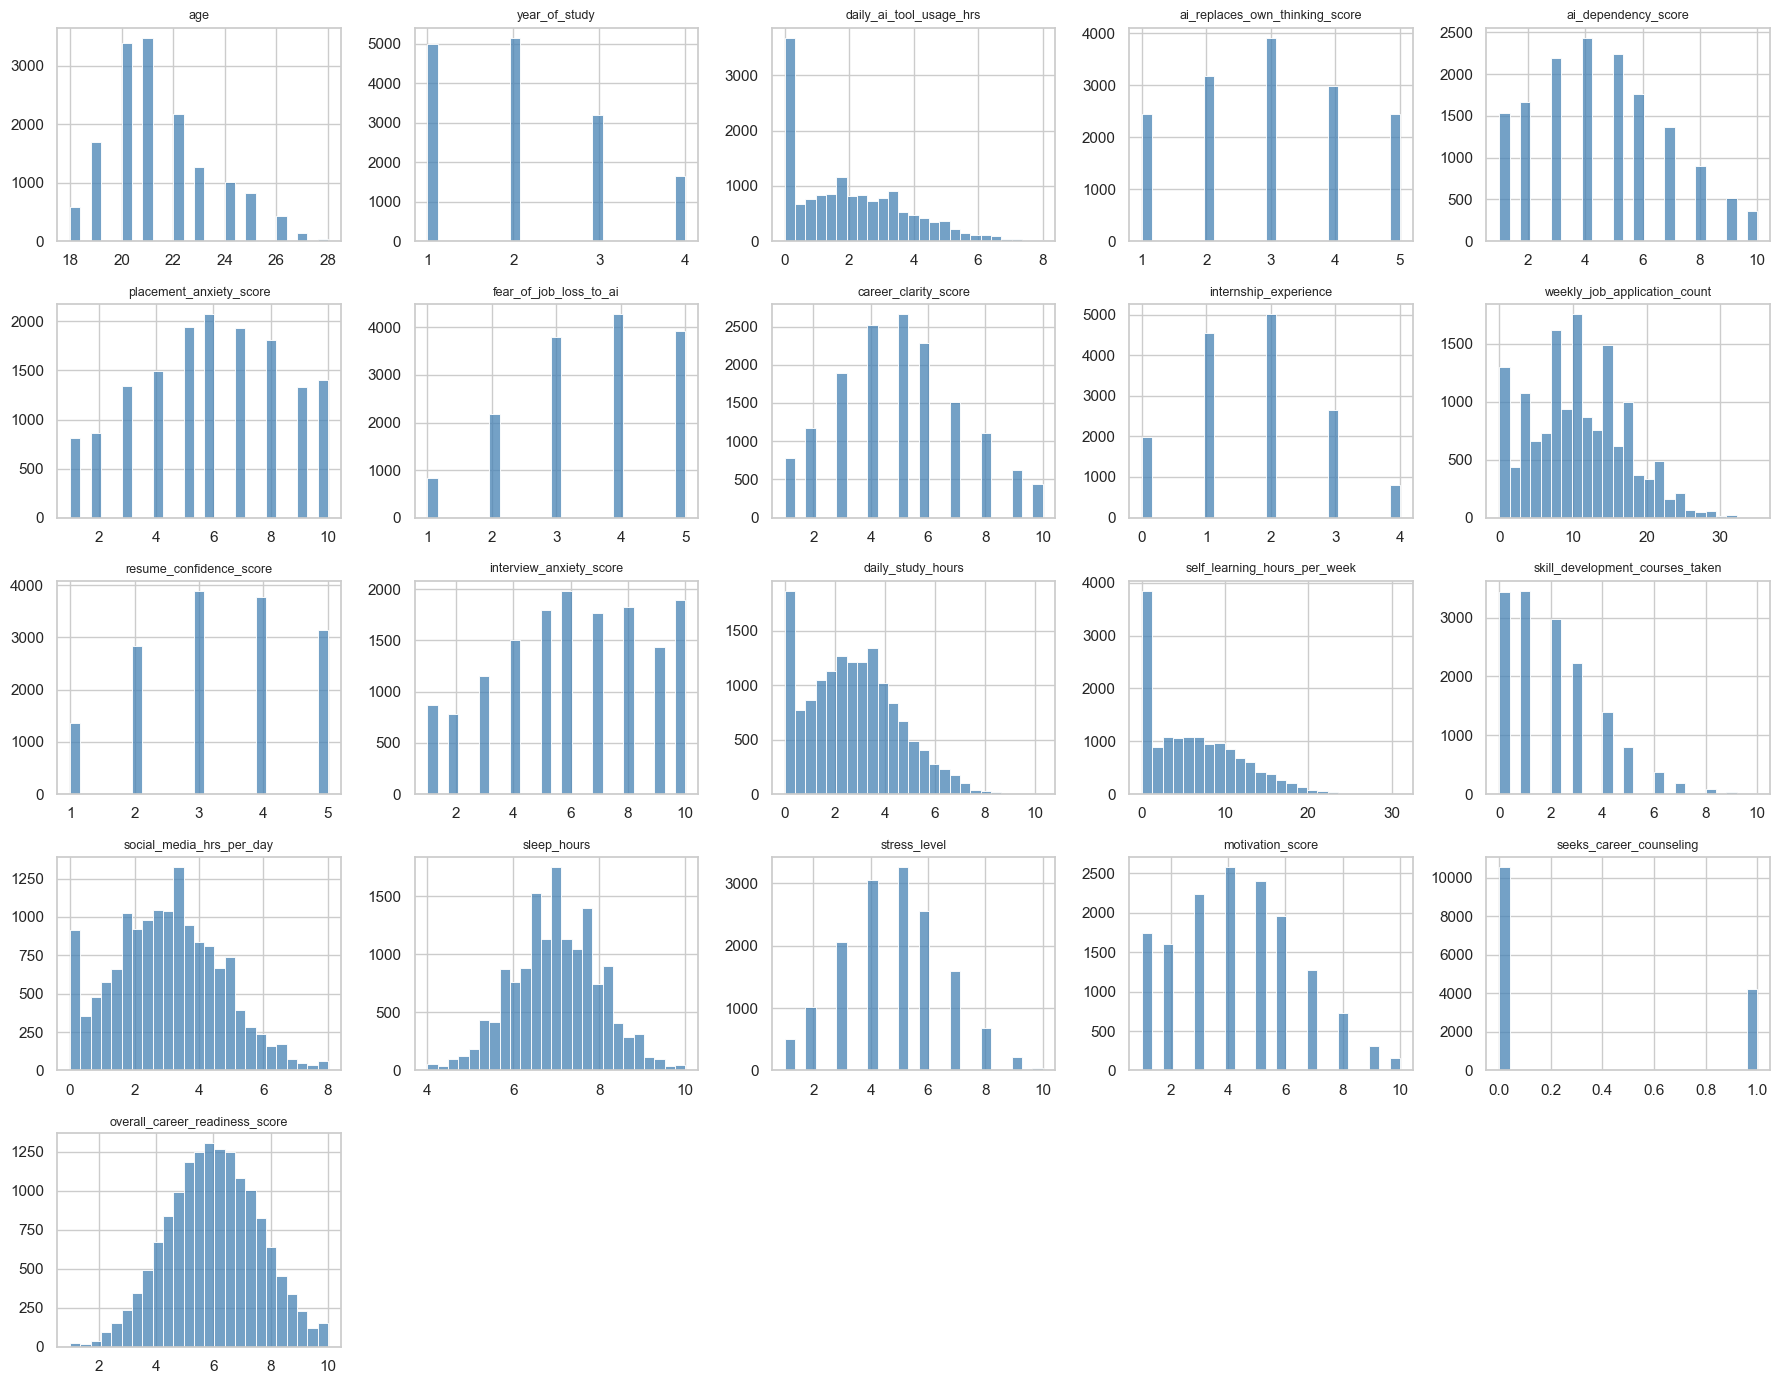

In [15]:
figure, grille_axes = plt.subplots(5, 5, figsize=(18, 14))
for axe, nom_colonne in zip(grille_axes.ravel(), num_cols):
    sns.histplot(df[nom_colonne], bins=25, ax=axe, color="steelblue")
    axe.set_title(nom_colonne, fontsize=9)
    axe.set_xlabel("")
    axe.set_ylabel("")
for axe in grille_axes.ravel()[len(num_cols):]:
    axe.axis("off")
plt.tight_layout()
plt.show()

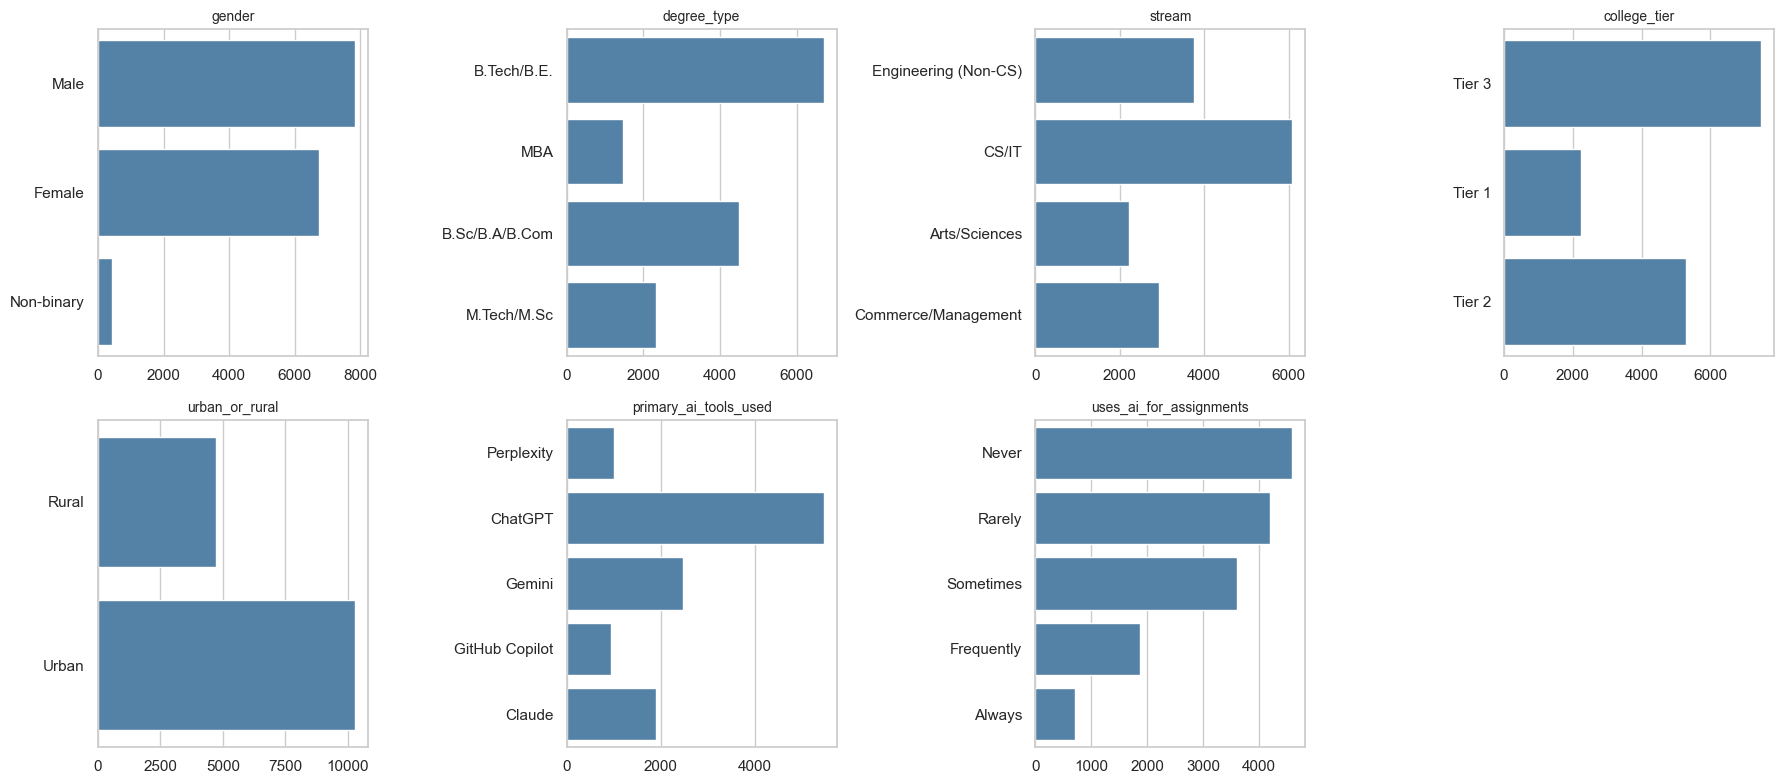

In [16]:
figure, grille_axes = plt.subplots(2, 4, figsize=(18, 8))
for axe, nom_colonne in zip(grille_axes.ravel(), cols_cat):
    sns.countplot(data=df, y=nom_colonne, ax=axe, color="steelblue")
    axe.set_title(nom_colonne, fontsize=10)
    axe.set_xlabel("")
    axe.set_ylabel("")
grille_axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

### Valeurs extrêmes (méthode IQR)

In [17]:
resume_ext = {}
for nom_colonne in num_cols:
    q1 = df[nom_colonne].quantile(0.25)
    q3 = df[nom_colonne].quantile(0.75)
    iqr = q3 - q1
    masque = (
        (df[nom_colonne] < q1 - 1.5 * iqr)
        | (df[nom_colonne] > q3 + 1.5 * iqr)
    )
    if masque.sum() > 0:
        resume_ext[nom_colonne] = masque.sum()

pd.Series(resume_ext, name="nombre_valeurs_extremes").sort_values(ascending=False)

internship_experience              809
age                                606
skill_development_courses_taken    330
sleep_hours                         72
social_media_hrs_per_day            71
weekly_job_application_count        56
stress_level                        46
self_learning_hours_per_week        45
daily_ai_tool_usage_hrs             41
daily_study_hours                   40
overall_career_readiness_score      31
Name: nombre_valeurs_extremes, dtype: int64

Ces valeurs extrêmes restent plausibles (par exemple 4 stages ou 28 ans). Ce ne sont pas des erreurs, on **ne les supprime pas**.

## 5. Exploration bivariée : lien avec le burnout

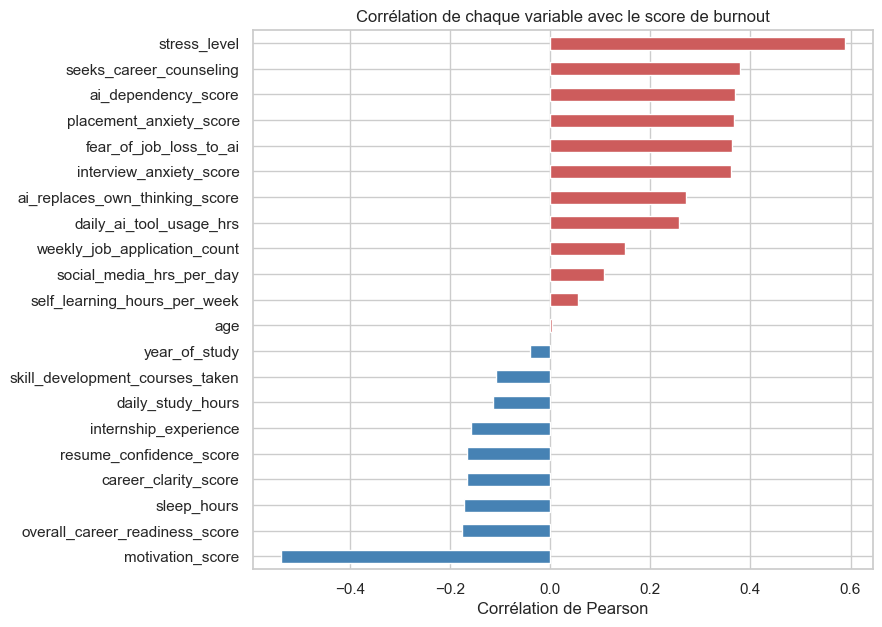

In [18]:
corr_burnout = (
    df[num_cols + ["burnout_score"]]
    .corr()["burnout_score"]
    .drop("burnout_score")
    .sort_values()
)

plt.figure(figsize=(8, 7))
couleurs = ["indianred" if valeur > 0 else "steelblue" for valeur in corr_burnout]
corr_burnout.plot(kind="barh", color=couleurs)
plt.title("Corrélation de chaque variable avec le score de burnout")
plt.xlabel("Corrélation de Pearson")
plt.show()

Points à retenir :
- `stress_level` (+0,59) et `motivation_score` (−0,54) sont de loin les plus liés.
- Viennent ensuite la dépendance à l'IA, les anxiétés (placement, entrevue, peur de perdre son emploi) autour de +0,36.
- `seeks_career_counseling` (+0,38) est probablement une **conséquence** du burnout et non une cause.

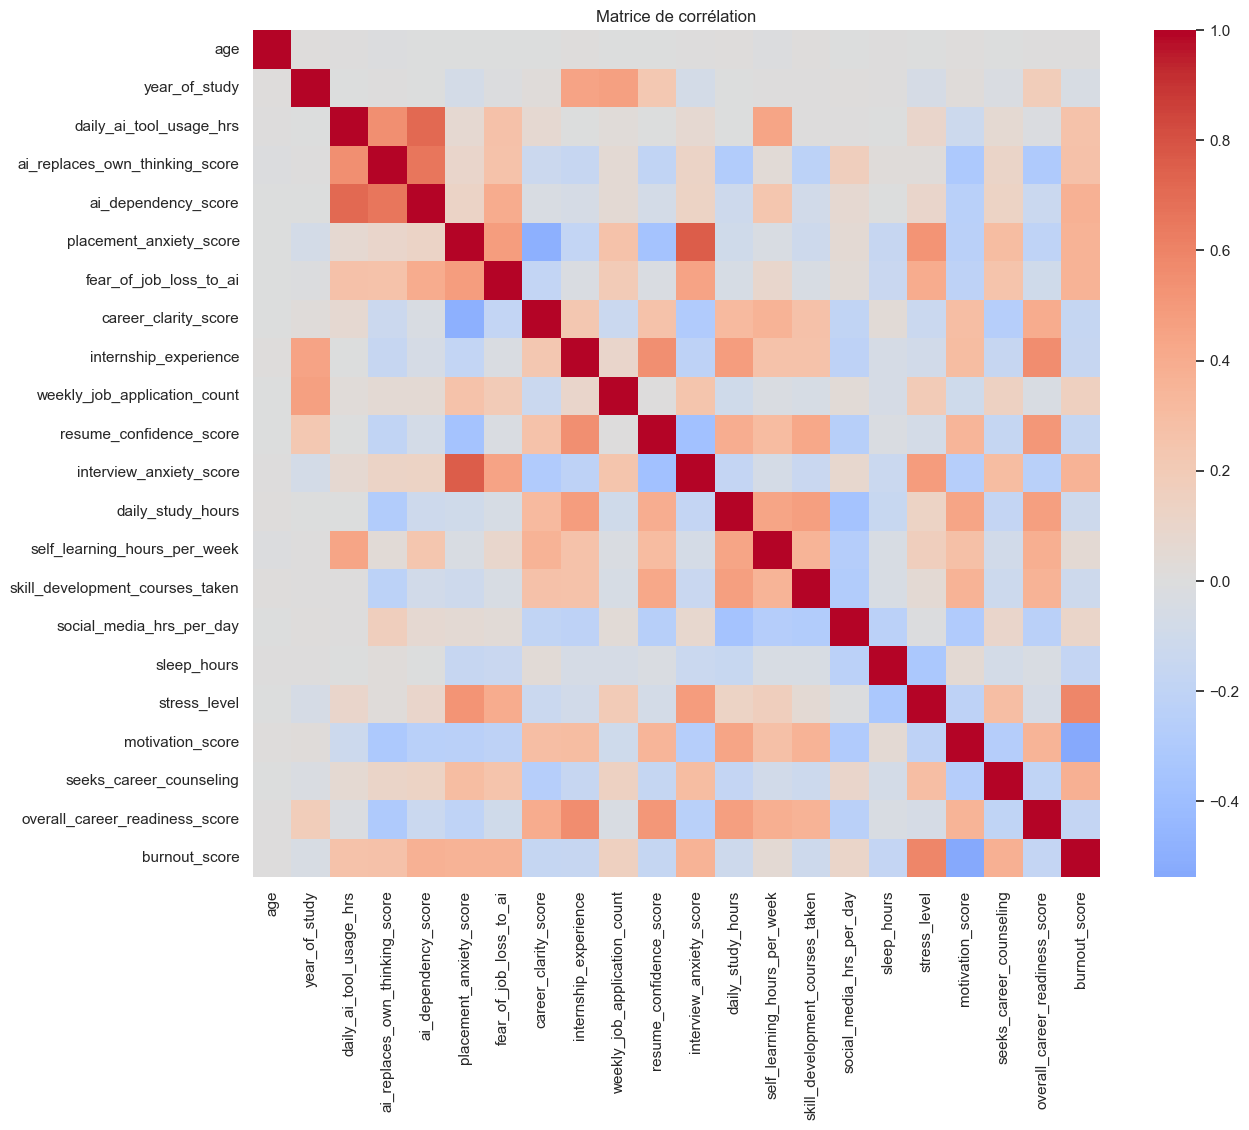

In [19]:
matrice_corr = df[num_cols + ["burnout_score"]].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(matrice_corr, cmap="coolwarm", center=0, annot=False, square=True)
plt.title("Matrice de corrélation")
plt.show()

### Variables fortement corrélées entre elles (multicolinéarité)

In [20]:
paires = matrice_corr.abs().where(np.triu(np.ones(matrice_corr.shape), k=1).astype(bool)).stack()
paires[paires > 0.5].sort_values(ascending=False).round(2)

placement_anxiety_score         interview_anxiety_score           0.76
daily_ai_tool_usage_hrs         ai_dependency_score               0.72
ai_replaces_own_thinking_score  ai_dependency_score               0.66
stress_level                    burnout_score                     0.59
internship_experience           overall_career_readiness_score    0.56
                                resume_confidence_score           0.55
daily_ai_tool_usage_hrs         ai_replaces_own_thinking_score    0.55
motivation_score                burnout_score                     0.54
placement_anxiety_score         stress_level                      0.53
resume_confidence_score         overall_career_readiness_score    0.51
dtype: float64

Plusieurs variables mesurent presque la même chose (anxiété de placement et d'entrevue : 0,76 ; usage d'IA et dépendance à l'IA : 0,72). Ce n'est pas grave pour un arbre ou une forêt, mais cela rend les coefficients d'une régression moins faciles à interpréter.

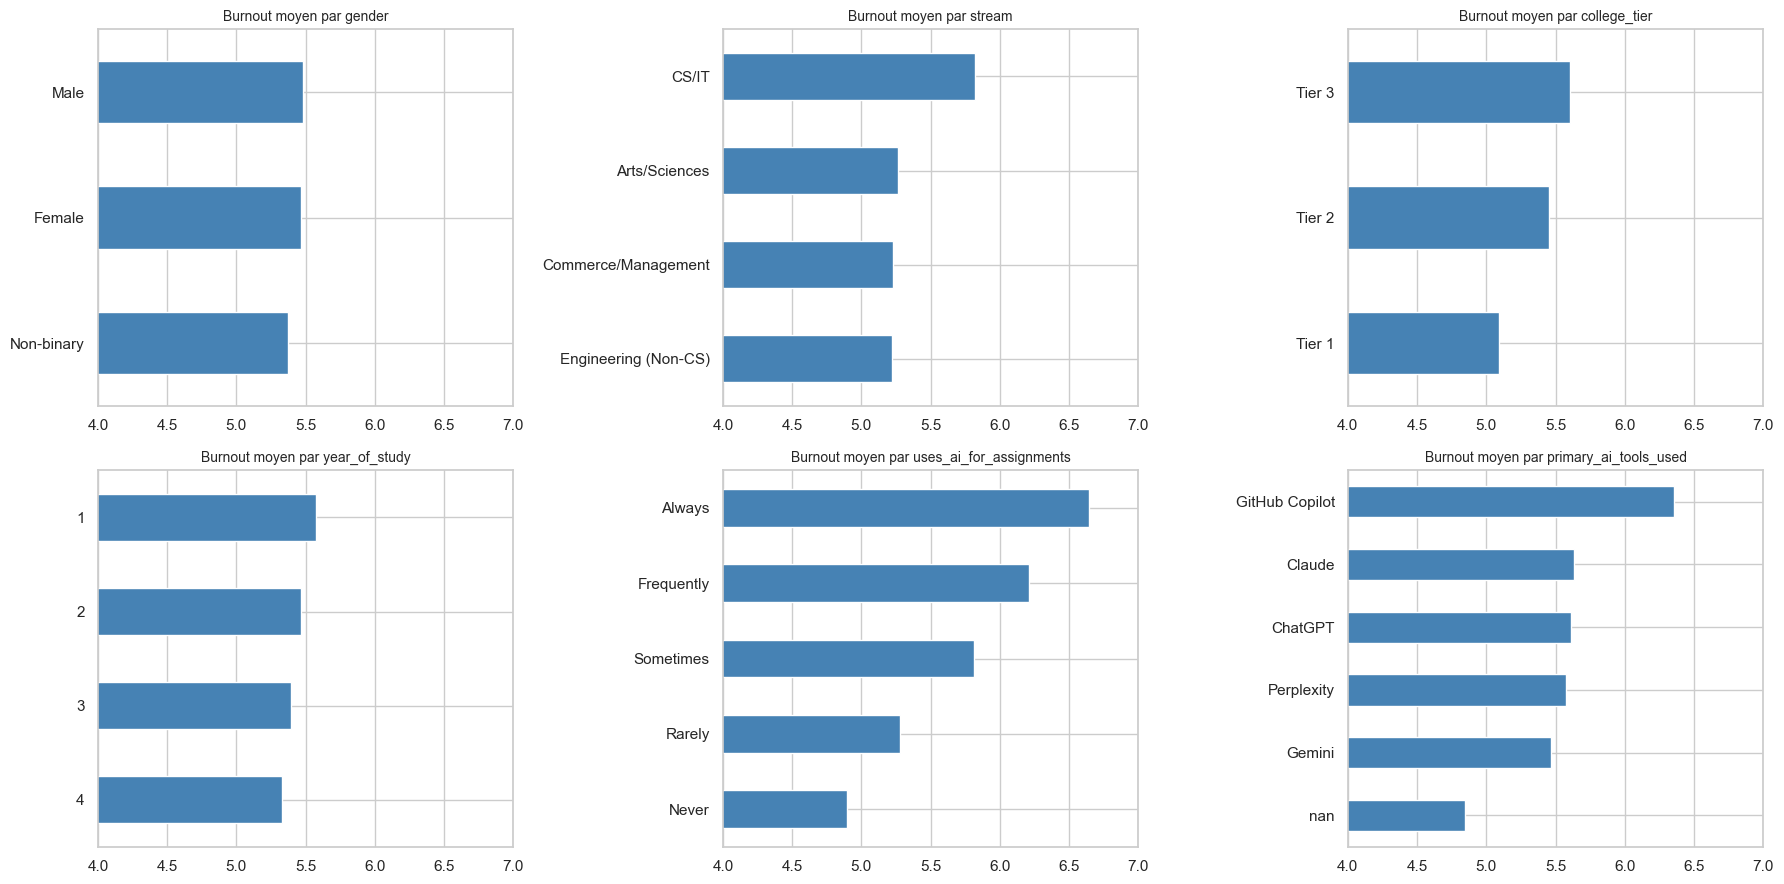

In [21]:
figure, grille_axes = plt.subplots(2, 3, figsize=(18, 9))
cols_comp = ["gender", "stream", "college_tier", "year_of_study", "uses_ai_for_assignments", "primary_ai_tools_used"]
for axe, nom_colonne in zip(grille_axes.ravel(), cols_comp):
    moy_groupe = df.groupby(nom_colonne, dropna=False)["burnout_score"].mean().sort_values()
    moy_groupe.plot(kind="barh", ax=axe, color="steelblue")
    axe.set_title("Burnout moyen par " + nom_colonne, fontsize=10)
    axe.set_xlim(4, 7)
    axe.set_ylabel("")
plt.tight_layout()
plt.show()

- **Aucun effet** visible du genre, de la zone urbaine/rurale ou du type de diplôme (moyennes quasi identiques).
- **Effet net de l'usage de l'IA pour les travaux** : de 4,9 (jamais) à 6,6 (toujours).
- Les étudiants en CS/IT et ceux de collèges de tier 3 sont un peu plus touchés.
- Les non-utilisateurs d'IA (valeur manquante) ont le burnout le plus bas (4,8).

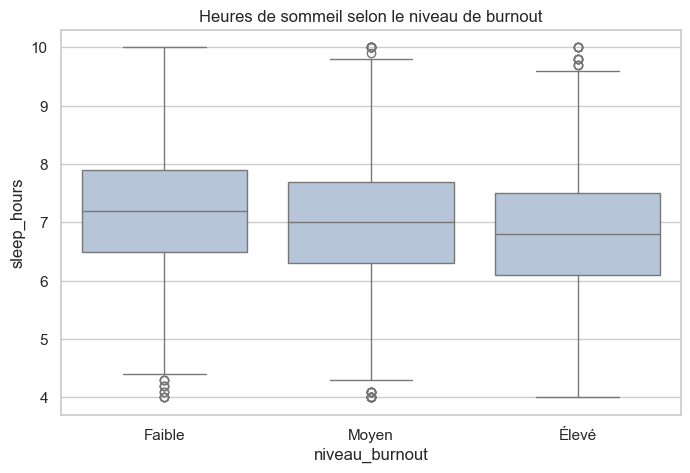

In [22]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="niveau_burnout", y="sleep_hours", order=["Faible", "Moyen", "Élevé"], color="lightsteelblue")
plt.title("Heures de sommeil selon le niveau de burnout")
plt.show()

# Partie 2 : préparation des données

## 6. Préparation des données

**Logique :** données brutes → nettoyage de base → ys → familles de colonnes → pipeline de prétraitement → séparation 60 / 20 / 20.

**Règle :** le jeu de **test** n'est pas utilisé. On le garde pour l'évaluation finale.

### 6.1 Ce qu'on prédit (y) et avec quoi (X)

Le projet comporte **deux problèmes de classification** qui partagent le même fichier (15 000 étudiants, 30 colonnes). Chacun a son propre y.

| | Volet 1 : risque d'épuisement | Volet 2 : soutien |
|---|---|---|
| **y** | `burnout_level` : 0 = Faible (score 1-4), 1 = Moyen (5-6), 2 = Élevé (7-10) | `seeks_career_counseling` : 0 = ne cherche pas, 1 = cherche un conseiller |
| **X** | 26 colonnes : profil, usage de l'IA, anxiété de carrière, préparation, habitudes de vie, stress et motivation | les mêmes 26 + `burnout_score` (décision d'équipe, voir 6.8) |
| **Lignes** | 15 000 | 14 780 (220 sans réponse retirées) |

**Colonnes exclues de X :** `student_id` (simple identifiant), `burnout_score` et `burnout_level` au volet 1 (c'est la réponse : fuite de données), `overall_career_readiness_score` (score global calculé à partir d'autres variables), `seeks_career_counseling` au volet 1 (probablement une conséquence de l'épuisement).

### 6.2 Imports et graine aléatoire

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

SEED = 42  # même graine partout = résultats reproductibles

### 6.3 Nettoyage de base

On repart des données brutes. Seule la colonne `niveau_burnout`, créée pour l'exploration, est retirée.

In [24]:
df_prep = df.drop(columns=["niveau_burnout"]).copy()
print("Dimensions de départ :", df_prep.shape)

Dimensions de départ : (15000, 30)


In [25]:
df_prep["primary_ai_tools_used"] = df_prep["primary_ai_tools_used"].fillna("Aucun")

print("Étudiants sans outil principal (« Aucun ») :", (df_prep["primary_ai_tools_used"] == "Aucun").sum())

Étudiants sans outil principal (« Aucun ») : 3215


### 6.4 Cible du volet 1 : `burnout_level`

On regroupe `burnout_score` (1 à 10) en 3 classes : 0 = Faible (1-4), 1 = Moyen (5-6), 2 = Élevé (7-10). Ce découpage est un choix de l'équipe, à valider (d'autres seuils pourront être testés à l'optimisation).

In [26]:
df_prep["burnout_level"] = pd.cut(
    df_prep["burnout_score"],
    bins=[0, 4, 6, 10],
    labels=[0, 1, 2],
).astype(int)

rep_level = df_prep["burnout_level"].value_counts().sort_index()
pd.DataFrame({
    "nombre": rep_level,
    "pourcentage": (rep_level / len(df_prep) * 100).round(1),
})

,nombre,pourcentage
burnout_level,,
0,4832,32.2
1,5461,36.4
2,4707,31.4


Les classes sont équilibrées : Faible 4 832 (32,2 %), Moyen 5 461 (36,4 %), Élevé 4 707 (31,4 %). Pas besoin de rééchantillonner.

### 6.5 Familles de colonnes

| Famille | Colonnes | Traitement |
|---|---|---|
| Numériques (19) | âge, heures, scores... | vides → médiane, puis `StandardScaler` |
| Ordinales (2) | `college_tier`, `uses_ai_for_assignments` | vides → valeur la plus fréquente, puis `OrdinalEncoder` (ordre respecté) |
| Nominales (5) | genre, diplôme, filière, milieu, outil d'IA | `OneHotEncoder` (une colonne 0/1 par valeur) |

L'ordre de `college_tier` (Tier 3 < Tier 2 < Tier 1) est un choix à confirmer.

In [27]:
ORD_COLS = ["college_tier", "uses_ai_for_assignments"]

ORD_CATS = [
    ["Tier 3", "Tier 2", "Tier 1"],                              # À VÉRIFIER : sens de l'ordre voulu
    ["Never", "Rarely", "Sometimes", "Frequently", "Always"],
]

NOM_COLS = ["gender", "degree_type", "stream", "urban_or_rural", "primary_ai_tools_used"]

In [28]:
# Colonnes à exclure de X (fuite de données ou inutiles)
cols_excl = ["student_id", "burnout_score", "burnout_level", "overall_career_readiness_score"]

TARGET_2 = "seeks_career_counseling"

num_cols_1 = [
    nom_colonne for nom_colonne in df_prep.columns
    if nom_colonne not in ORD_COLS + NOM_COLS + cols_excl + [TARGET_2]
]

print("Numériques :", len(num_cols_1))
print("Ordinales  :", len(ORD_COLS))
print("Nominales  :", len(NOM_COLS))
print("Total de X :", len(num_cols_1) + len(ORD_COLS) + len(NOM_COLS))

Numériques : 19
Ordinales  : 2
Nominales  : 5
Total de X : 26


### 6.6 Pipeline de prétraitement et séparation

**Éviter les fuites de données :** (1) la cible et ses dérivés sont exclus de X ; (2) le prétraitement est dans un `Pipeline` : médiane, échelle et encodage sont **appris sur l'entraînement seulement**, puis appliqués à la validation et au test.

**Séparation :** 60 % entraînement, 20 % validation, 20 % test, **stratifiée** (mêmes proportions de classes dans chaque morceau).

In [29]:
def build_preprocessor(num_cols):
    """Prétraitement appris sur l'entraînement seulement (le pipeline s'en occupe)."""
    num_pipe  = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    ord_pipe  = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(categories=ORD_CATS)),
    ])
    return ColumnTransformer([
        ("numerique", num_pipe , num_cols),
        ("ordinal", ord_pipe , ORD_COLS),
        ("nominal", OneHotEncoder(handle_unknown="ignore"), NOM_COLS),
    ])

In [30]:
def split_60_20_20(X, y):
    """60 % train / 20 % val / 20 % test, stratifié (mêmes proportions de classes)."""
    X_tmp, X_test, y_tmp, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=SEED
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED
    )
    return (X_train, X_val, X_test,
            y_train, y_val , y_test )

### 6.7 Volet 1 : niveau de risque d'épuisement (3 classes)

In [31]:
cols_1 = num_cols_1 + ORD_COLS + NOM_COLS

X1 = df_prep[cols_1]
y1 = df_prep["burnout_level"]

X1_train, X1_val, X1_test, y1_train, y1_val, y1_test = split_60_20_20(X1, y1)

print("Volet 1 (train / val / test) :", len(X1_train), len(X1_val), len(X1_test))

Volet 1 (train / val / test) : 9000 3000 3000


### 6.8 Volet 2 : propension à consulter un conseiller (binaire)

On retire les lignes sans réponse à `seeks_career_counseling` (environ 1,5 %).

**Décision d'équipe à noter :** le volet 2 utilise-t-il `burnout_score` comme variable ? Ici `True`, comme au Jalon 1 (le soutien dépend du niveau d'épuisement). En production, ce serait la valeur **prédite** par le volet 1, pas le vrai score : les résultats sont donc un peu optimistes. Mettre `False` pour tester sans.

In [32]:
df_2 = df_prep.dropna(subset=[TARGET_2]).copy()
df_2[TARGET_2] = df_2[TARGET_2].astype(int)

USE_BURNOUT_SCORE = True  # décision d'équipe : vrai score (optimiste) ou non

num_cols_2 = num_cols_1 + (["burnout_score"] if USE_BURNOUT_SCORE else [])
cols_2 = num_cols_2 + ORD_COLS + NOM_COLS

X2 = df_2[cols_2]
y2 = df_2[TARGET_2]

X2_train, X2_val, X2_test, y2_train, y2_val, y2_test = split_60_20_20(X2, y2)

print("Lignes retirées (pas de réponse) :", len(df_prep) - len(df_2))
print("Volet 2 (train / val / test) :", len(X2_train), len(X2_val), len(X2_test))

Lignes retirées (pas de réponse) : 220
Volet 2 (train / val / test) : 8868 2956 2956


# Partie 3 : modélisation (3 modèles × 2 volets)

## 7. Modélisation

**Logique :** pour chaque volet, le même prétraitement + chaque modèle sont collés dans un `Pipeline`, entraînés sur l'**entraînement**, puis comparés sur la **validation**. Chaque essai ajoute une ligne au tableau de résultats.

**Les 3 modèles :** régression logistique (référence simple et explicable), Random Forest (arbres qui votent), gradient boosting (arbres qui corrigent les erreurs des précédents). Réglages par défaut : l'optimisation vient ensuite.

**Métriques :** volet 1 : accuracy, F1 macro, rappel de la classe « Élevé ». Volet 2 : accuracy, F1, rappel et précision de la classe « oui ».

### 7.1 Outils : modèles et fonction d'évaluation

In [33]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score,
                             confusion_matrix, precision_recall_curve)

resultats = []   # chaque essai = une ligne (base du suivi des expériences)


def get_models(cw=None):
    """3 modèles : référence simple + 2 modèles à base d'arbres."""
    return {
        "Régression logistique": LogisticRegression(max_iter=1000, class_weight=cw),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight=cw,
                                                random_state=SEED, n_jobs=-1),
        "Gradient boosting": HistGradientBoostingClassifier(class_weight=cw,
                                                            random_state=SEED),
    }


def evaluer(volet, X_train, y_train, X_val, y_val, num_cols,
                    configuration, cw=None, binaire=False):
    """Entraîne les 3 modèles sur l'entraînement, les évalue sur la validation, note les résultats."""
    preparateur = build_preprocessor(num_cols)
    modeles = {}
    for nom_modele, modele in get_models(cw).items():
        chaine = Pipeline([("preparation", clone(preparateur)), ("modele", modele)])  # copie neuve du prétraitement
        chaine.fit(X_train, y_train)            # APPREND sur l'entraînement seulement
        predictions = chaine.predict(X_val)   # prédit sur la validation (données jamais vues)
        ligne = {"volet": volet, "configuration": configuration, "modèle": nom_modele,
                 "accuracy": accuracy_score(y_val, predictions)}
        if binaire:    # volet 2 : on suit la classe « oui » (1)
            ligne.update(f1_oui=f1_score(y_val, predictions), rappel_oui=recall_score(y_val, predictions),
                         precision_oui=precision_score(y_val, predictions))
        else:          # volet 1 : F1 macro + rappel de la classe « Élevé » (2)
            ligne.update(f1_macro=f1_score(y_val, predictions, average="macro"),
                         rappel_eleve=recall_score(y_val, predictions, labels=[2], average="macro"))
        resultats.append(ligne)
        modeles[nom_modele] = chaine
    return modeles

### 7.2 Volet 1 : niveau d'épuisement (avec et sans `stress_level`)

In [34]:
# Essai A : avec stress_level
m1 = evaluer("1-épuisement", X1_train, y1_train, X1_val, y1_val,
             num_cols_1, "avec stress_level")

# Essai B : sans stress_level (question ouverte du Jalon 1)
num_sans = [c for c in num_cols_1 if c != "stress_level"]
cols_sans = num_sans + ORD_COLS + NOM_COLS
m1_sans = evaluer("1-épuisement", X1_train[cols_sans], y1_train, X1_val[cols_sans], y1_val,
                  num_sans, "sans stress_level")

print(pd.DataFrame(resultats).round(3).to_string(index=False))

# Matrice de confusion de la régression logistique (lignes = réel, colonnes = prédit : Faible, Moyen, Élevé)
print(confusion_matrix(y1_val, m1["Régression logistique"].predict(X1_val)))

C:\Users\mpian\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\mpian\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\mpian\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\mpian\AppData\Roaming\Python\Pytho

       volet     configuration                modèle  accuracy  f1_macro  rappel_eleve
1-épuisement avec stress_level Régression logistique     0.627     0.633         0.683
1-épuisement avec stress_level         Random Forest     0.602     0.609         0.644
1-épuisement avec stress_level     Gradient boosting     0.603     0.609         0.645
1-épuisement sans stress_level Régression logistique     0.574     0.579         0.639
1-épuisement sans stress_level         Random Forest     0.557     0.563         0.584
1-épuisement sans stress_level     Gradient boosting     0.565     0.570         0.615
[[665 266  35]
 [274 574 244]
 [ 28 271 643]]


C:\Users\mpian\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\mpian\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\mpian\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\mpian\AppData\Roaming\Python\Pytho

**Résultats du volet 1 (validation, 3 000 étudiants)**

| Modèle | Accuracy avec stress | F1 macro | Rappel « Élevé » | Accuracy sans stress |
|---|---|---|---|---|
| Régression logistique | 62,7 % | 0,633 | 0,683 | 57,4 % |
| Random Forest | 60,2 % | 0,609 | 0,644 | 55,7 % |
| Gradient boosting | 60,3 % | 0,609 | 0,645 | 56,5 % |
| Référence (classe majoritaire) | 36 % | | | |

**Analyse**
- Les trois modèles font nettement mieux que la référence (36 %), mais restent sous la cible initiale de 65 % (à réviser dans le cahier, en orange).
- La régression logistique est la meilleure, et les modèles plus complexes ne font pas mieux : les relations sont surtout linéaires. Les écarts entre modèles de 1 à 2 points sont du même ordre que l'incertitude d'une seule validation (environ ±1 point), à confirmer par validation croisée.
- `stress_level` pèse lourd : le retirer fait perdre 4 à 5 points à chaque modèle.
- Matrice de confusion (régression logistique) : les erreurs se font surtout entre classes voisines. Seulement 35 « Faible » classés « Élevé » et 28 « Élevé » classés « Faible », soit 63 sur 3 000.

### 7.3 Volet 2 : propension à consulter un conseiller

In [35]:
# class_weight="balanced" : donne plus de poids à la classe « oui » (seulement 29 %)
m2 = evaluer("2-soutien", X2_train, y2_train, X2_val, y2_val, num_cols_2,
             f"équilibré, burnout_score={USE_BURNOUT_SCORE}",
             cw="balanced", binaire=True)

print(pd.DataFrame(resultats).query("volet == '2-soutien'").round(3).to_string(index=False))

C:\Users\mpian\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\mpian\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\mpian\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\mpian\AppData\Roaming\Python\Pytho

    volet                 configuration                modèle  accuracy  f1_macro  rappel_eleve  f1_oui  rappel_oui  precision_oui
2-soutien équilibré, burnout_score=True Régression logistique     0.710       NaN           NaN   0.599       0.756          0.496
2-soutien équilibré, burnout_score=True         Random Forest     0.772       NaN           NaN   0.494       0.388          0.678
2-soutien équilibré, burnout_score=True     Gradient boosting     0.730       NaN           NaN   0.603       0.716          0.521


**Résultats du volet 2 (validation, `class_weight="balanced"`, avec `burnout_score`)**

| Modèle | Accuracy | F1 « oui » | Rappel « oui » | Précision « oui » |
|---|---|---|---|---|
| Régression logistique | 71,0 % | 0,599 | 0,756 | 0,496 |
| Gradient boosting | 73,0 % | 0,603 | 0,716 | 0,521 |
| Random Forest | 77,2 % | 0,494 | 0,388 | 0,678 |

**Analyse**
- Random Forest a la meilleure accuracy, mais il rate 6 « oui » sur 10 : c'est le piège de l'accuracy sur une classe rare.
- Régression logistique et gradient boosting détectent 7 « oui » sur 10, au prix de nombreuses fausses alertes (précision d'environ 0,5).
- La pondération des classes a fait passer le rappel de 0,40 (Jalon 1, sans pondération) à plus de 0,70.

**Décision d'équipe à noter dans le journal :** on utilise ici le vrai `burnout_score` comme variable (comme au Jalon 1). En situation réelle, on n'aurait que le niveau **prédit** par le volet 1 : les résultats sont donc un peu optimistes. Mettre `USE_BURNOUT_SCORE = False` pour tester sans.

### 7.4 Ajustement du seuil de décision du volet 2 (objectif : rappel « oui » ≥ 0,60)

In [36]:
best_2 = m2["Régression logistique"]
proba = best_2.predict_proba(X2_val)[:, 1]   # probabilité d'être « oui »
precisions, rappels, seuils = precision_recall_curve(y2_val, proba)

idx = np.where(rappels[:-1] >= 0.60)[0]
if len(idx):
    i = idx[-1]      # le seuil le plus élevé qui respecte encore le rappel visé
    print(f"Seuil = {seuils[i]:.2f} -> rappel = {rappels[i]:.2f}, précision = {precisions[i]:.2f}")

Seuil = 0.64 -> rappel = 0.60, précision = 0.59


**Interprétation :** en relevant le seuil de décision de la régression logistique à 0,64, on obtient un rappel de 0,60 (objectif) avec une précision de 0,59 : on détecte 6 « oui » sur 10 et 6 alertes sur 10 sont justes. Le seuil a été choisi sur la validation ; il sera revérifié à l'optimisation.

### 7.5 Test de sensibilité : autre découpage de la cible du volet 1

In [37]:
# Régression logistique seule, mêmes colonnes et même séparation, pour 4 découpages de burnout_score
decoupages = {
    "A : 1-3 / 4-6 / 7-10": [0, 3, 6, 10],
    "B : 1-4 / 5-6 / 7-10 (retenu)": [0, 4, 6, 10],
    "C : 1-3 / 4-7 / 8-10": [0, 3, 7, 10],
    "D : 1-4 / 5-7 / 8-10": [0, 4, 7, 10],
}
lignes_dec = []
for nom_dec, bornes in decoupages.items():
    y_alt = pd.cut(df_prep["burnout_score"], bins=bornes, labels=[0, 1, 2]).astype(int)
    X_train, X_val, _, y_train, y_val, _ = split_60_20_20(X1, y_alt)
    chaine = Pipeline([("preparation", build_preprocessor(num_cols_1)),
                       ("modele", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
    pred = chaine.predict(X_val)
    parts = (y_alt.value_counts(normalize=True).sort_index() * 100).round(0).astype(int).tolist()
    lignes_dec.append({
        "découpage": nom_dec, "classes (%)": parts, "référence majoritaire (%)": max(parts),
        "accuracy": round(accuracy_score(y_val, pred), 3),
        "F1 macro": round(f1_score(y_val, pred, average="macro"), 3),
        "rappel Élevé": round(recall_score(y_val, pred, labels=[2], average="macro"), 3),
    })
pd.DataFrame(lignes_dec)

,découpage,classes (%),référence majoritaire (%),accuracy,F1 macro,rappel Élevé
0,A : 1-3 / 4-6 / 7-10,"[18, 51, 31]",51,0.655,0.625,0.619
1,B : 1-4 / 5-6 / 7-10 (retenu),"[32, 36, 31]",36,0.627,0.633,0.683
2,C : 1-3 / 4-7 / 8-10,"[18, 65, 17]",65,0.746,0.643,0.460
3,D : 1-4 / 5-7 / 8-10,"[32, 51, 17]",51,0.680,0.645,0.455


**Interprétation et décision.** L'accuracy plus haute des découpages A, C et D est **trompeuse** : leur classe majoritaire est plus grosse (51 % ou 65 %), donc leur référence aussi. Le gain du découpage B sur sa référence est d'environ 27 points (62,7 % contre 36 %), contre environ 14 points pour A. B a aussi le meilleur rappel pour la classe « Élevé » (0,68, contre 0,46 pour C et D), ce qui compte le plus : ne pas rater un étudiant à risque. **On garde B (1-4 / 5-6 / 7-10).** À nuancer : un seul modèle, une seule séparation, des écarts de F1 macro faibles ; les autres découpages seront retestés à l'optimisation avec validation croisée.

### 7.6 Tableau de résultats

In [38]:
tab_res = pd.DataFrame(resultats).round(3)
print(tab_res.to_string(index=False))
tab_res.to_csv("resultats_experiences.csv", index=False)

       volet                 configuration                modèle  accuracy  f1_macro  rappel_eleve  f1_oui  rappel_oui  precision_oui
1-épuisement             avec stress_level Régression logistique     0.627     0.633         0.683     NaN         NaN            NaN
1-épuisement             avec stress_level         Random Forest     0.602     0.609         0.644     NaN         NaN            NaN
1-épuisement             avec stress_level     Gradient boosting     0.603     0.609         0.645     NaN         NaN            NaN
1-épuisement             sans stress_level Régression logistique     0.574     0.579         0.639     NaN         NaN            NaN
1-épuisement             sans stress_level         Random Forest     0.557     0.563         0.584     NaN         NaN            NaN
1-épuisement             sans stress_level     Gradient boosting     0.565     0.570         0.615     NaN         NaN            NaN
   2-soutien équilibré, burnout_score=True Régression logistiq

Ce tableau est la base de notre **suivi des expériences** : une ligne par modèle et par configuration. Chaque nouvel essai d'optimisation y sera ajouté.

## 8. Conclusion de cette étape (préparation + premiers modèles)

**Ce qui est fait**
- Exploration des données : types, doublons (0), valeurs manquantes (4 081 cases, 5 colonnes), valeurs extrêmes (réalistes, conservées), répartition des deux ys.
- Préparation : recodage, imputation, encodage, mise à l'échelle, séparation stratifiée 60/20/20, le tout dans un pipeline qui évite les fuites de données.
- Modélisation : 3 modèles de classification testés sur chacun des deux volets, comparés sur la validation, résultats consignés dans un tableau.

**Ce qu'on retient**
- **Volet 1 :** la régression logistique est la meilleure (accuracy 62,7 %, F1 macro 0,63, rappel « Élevé » 0,68), loin devant la référence de 36 %. La cible de 65 % n'est pas atteinte. Le stress et la motivation sont les facteurs dominants ; sans le stress, la performance baisse de 4 à 5 points.
- **Volet 2 :** avec la pondération des classes, la régression logistique et le gradient boosting atteignent un rappel de 0,72 à 0,76 (F1 ≈ 0,60). Random Forest est écarté à ce stade (rappel 0,39). Un seuil ajusté permet de viser un rappel de 0,60 avec une précision de 0,59.

**Limites à ce stade**
- Données synthétiques : les relations sont simulées et ne se généralisent pas automatiquement à de vrais étudiants.
- Une seule séparation de validation, donc des écarts de 1 à 2 points entre modèles ne sont pas concluants.
- Réglages par défaut seulement : aucune optimisation n'a encore été faite.
- Le test n'a pas été utilisé : aucune estimation finale de la performance.

**Décisions à prendre / à noter :** `burnout_score` vrai ou prédit dans le volet 2 ; garder ou non `stress_level` ; révision des ys de 65 % (sections 1.4 et 1.5 du cahier, en orange).

## Prochaines étapes (optimisation)

1. Validation croisée (5 plis) sur l'entraînement pour comparer les modèles de façon plus fiable.
2. Réglage des hyperparamètres de la régression logistique et du gradient boosting (`GridSearchCV` ; métrique : F1 macro au volet 1, F1 de la classe « oui » au volet 2).
3. Tester d'autres regroupements de `burnout_score` et le volet 2 avec le niveau d'épuisement **prédit**.
4. Ajuster le seuil de décision du volet 2 (rappel visé : 0,60).
5. Consigner chaque essai dans `resultats_experiences.csv`.
6. Choisir le modèle retenu, puis ouvrir le **test une seule fois** pour l'évaluation finale (Jalon 2).

## Conclusion provisoire du projet

> Le projet n'est pas terminé : cette conclusion sera mise à jour au Jalon 3.

**Ce que le projet montre jusqu'ici:** À partir de données académiques, comportementales et personnelles (dont l'usage de l'IA et l'anxiété de carrière), un modèle simple peut estimer le niveau de risque d'épuisement d'un étudiant bien au-delà du hasard (environ 63 % de bonnes classifications contre 36 % pour la référence), et repérer environ 7 étudiants sur 10 susceptibles de chercher un conseiller, au prix de nombreuses fausses alertes (précision d'environ 0,5 avant ajustement du seuil). Les facteurs les plus associés à l'épuisement dans ces données sont le stress et la motivation, puis la dépendance à l'IA et l'anxiété de carrière.

**Ce que le projet ne montre pas:** Les données sont synthétiques : ces résultats démontrent une méthode, pas une réalité sur de vrais étudiants. Le score d'épuisement n'est pas clinique et la consultation d'un conseiller est un comportement, pas un besoin diagnostiqué. L'outil estime un niveau de risque pour orienter le soutien ; il ne remplace ni un diagnostic ni un professionnel.

**Ce qu'il reste à faire:**
- Optimiser les modèles et évaluer le modèle retenu sur le jeu de test (Jalon 2).
- Définir la règle de type de soutien (psychologique, carrière, usage de l'IA) à partir des facteurs dominants.
- Vérifier l'équité du modèle selon le genre, le niveau d'établissement et le milieu (le groupe « Non-binary » compte 424 étudiants).
- Construire le prototype de tableau de bord, documenter le suivi, la maintenance, les limites et les risques éthiques (Jalon 3).